# Município e credores x churn

Duas perguntas, nenhuma com relação clara com o churn:

1. Município (e região) tem relação com o churn?
2. Credores do Serasa (quantidade, e cruzando com negativações, pedidos e porte) têm relação com o churn?

In [1]:
import os

import matplotlib.pyplot as plot
import numpy as np
import pandas
import seaborn
from scipy import stats
from IPython.display import display

seaborn.set_theme(style='ticks', context='paper', palette='plasma')
COR = '#f89441'

# Onde estão os CSVs: pasta data/ do repositório (local), arquivos soltos no Colab ou no Drive.
# Se não achar em nenhum lugar (Colab sem os arquivos), abre o seletor para você enviar os dois CSVs.
ARQ_LEADS, ARQ_PEDIDOS = 'churn_aplicacao_leads_final.csv', 'churn_comportamental_pedidos_final.csv'
for PASTA in ['../data', 'data', '.', '/content', '/content/drive/MyDrive/data']:
    if os.path.exists(f'{PASTA}/{ARQ_LEADS}') and os.path.exists(f'{PASTA}/{ARQ_PEDIDOS}'):
        break
else:
    from google.colab import files
    print(f'Selecione os arquivos {ARQ_LEADS} e {ARQ_PEDIDOS}')
    files.upload()   # salva na pasta atual do Colab
    PASTA = '.'

leads = pandas.read_csv(f'{PASTA}/{ARQ_LEADS}')
pedidos = pandas.read_csv(f'{PASTA}/{ARQ_PEDIDOS}')
print(f'{len(leads)} leads | taxa de churn geral: {leads.churned.mean():.1%}')


def qui2(df, coluna):
    p = stats.chi2_contingency(pandas.crosstab(df[coluna], df['churned']))[1]
    return p


def taxa(df, coluna, ordem=None):
    t = df.groupby(coluna, observed=True)['churned'].agg(leads='count', taxa_churn='mean')
    t['taxa_churn'] = (t['taxa_churn'] * 100).round(1)
    return t if ordem is None else t.reindex(ordem)


def barras_taxa(tabela, ax, titulo, rotacao=0):
    # barras com a taxa de churn e o n de cada categoria; linha tracejada = taxa geral
    ax.bar(tabela.index.astype(str), tabela['taxa_churn'] / 100, color=COR)
    for i, (n, t) in enumerate(zip(tabela['leads'], tabela['taxa_churn'])):
        ax.text(i, t / 100 + 0.01, f'{t:.0f}%\nn={n}', ha='center', va='bottom', fontsize=8)
    ax.axhline(leads['churned'].mean(), color='gray', linestyle='--', label=f'média geral ({leads["churned"].mean():.0%})')
    ax.set_ylim(0, 0.8)
    ax.set_title(titulo)
    ax.set_ylabel('taxa de churn')
    ax.tick_params(axis='x', rotation=rotacao)
    ax.legend(loc='upper right')

2000 leads | taxa de churn geral: 45.2%


---
# 1. Município e região

Um valor de `municipio` tem dígitos (parece nome de pessoa + CPF, provável erro de preenchimento). Não tratei, só deixo de mostrar:

In [2]:
estranhos = leads['municipio'].str.contains(r'\d')
print(f'{estranhos.sum()} lead com dígitos no município (fora da tabela abaixo para não expor o dado)')

1 lead com dígitos no município (fora da tabela abaixo para não expor o dado)


In [3]:
por_municipio = taxa(leads[~estranhos], 'municipio').sort_values('leads', ascending=False)
por_municipio.head(12)

,leads,taxa_churn
municipio,,
FORTALEZA,1333,46.1
CAUCAIA,149,51.0
MARACANAU,101,43.6
EUSEBIO,60,45.0
AQUIRAZ,57,50.9
BATURITE,50,46.0
CASCAVEL,30,40.0
PACAJUS,26,50.0
PARACURU,26,26.9


- Fortaleza tem 2/3 dos leads e vários municípios têm de 1 a 5 leads, então as taxas dos pequenos (0% ou 100%) não dizem nada
- Para o teste, municípios com menos de 30 leads viram "Outros"

In [4]:
contagem = leads['municipio'].value_counts()
leads['municipio_agrupado'] = leads['municipio'].where(leads['municipio'].map(contagem) >= 30, 'Outros')

print(f'qui-quadrado município (≥ 30 leads) x churn: p = {qui2(leads, "municipio_agrupado"):.3f}')
taxa(leads, 'municipio_agrupado').sort_values('taxa_churn', ascending=False)

qui-quadrado município (≥ 30 leads) x churn: p = 0.127


,leads,taxa_churn
municipio_agrupado,,
CAUCAIA,149,51.0
AQUIRAZ,57,50.9
FORTALEZA,1333,46.1
BATURITE,50,46.0
EUSEBIO,60,45.0
MARACANAU,101,43.6
CASCAVEL,30,40.0
Outros,220,35.9


Agrupando em Fortaleza / Região Metropolitana (RMF) / interior. A lista da RMF foi escrita à mão, vale conferir com a composição oficial.

In [5]:
RMF = ['CAUCAIA', 'MARACANAU', 'MARANGUAPE', 'PACATUBA', 'ITAITINGA', 'EUSEBIO', 'AQUIRAZ', 'GUAIUBA', 'HORIZONTE',
       'PACAJUS', 'CHOROZINHO', 'SAO GONCALO DO AMARANTE', 'PINDORETAMA', 'CASCAVEL', 'PARACURU', 'PARAIPABA',
       'TRAIRI', 'SAO LUIS DO CURU']

leads['regiao'] = np.select([leads['municipio'] == 'FORTALEZA', leads['municipio'].isin(RMF)], ['Fortaleza', 'RMF'], 'Interior')
leads['capital'] = np.where(leads['regiao'] == 'Fortaleza', 'Fortaleza', 'Fora da capital')

print(f'região (3 grupos): p = {qui2(leads, "regiao"):.3f} | capital x fora: p = {qui2(leads, "capital"):.3f}')
por_regiao = taxa(leads, 'regiao', ['Fortaleza', 'RMF', 'Interior'])
por_regiao

região (3 grupos): p = 0.359 | capital x fora: p = 0.295


,leads,taxa_churn
regiao,,
Fortaleza,1333,46.1
RMF,570,44.2
Interior,97,39.2


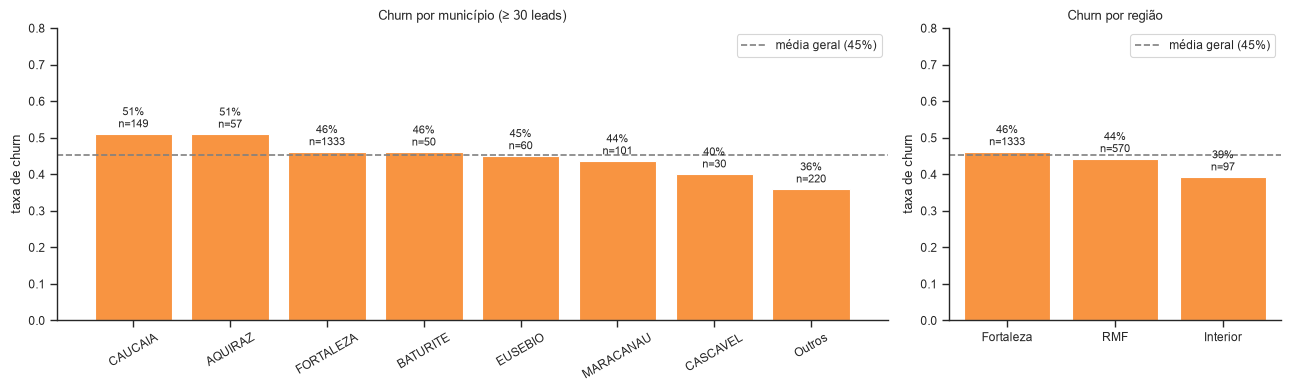

In [6]:
ordem_mun = taxa(leads, 'municipio_agrupado').sort_values('taxa_churn', ascending=False)
fig, (ax1, ax2) = plot.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2.5, 1]})
barras_taxa(ordem_mun, ax1, 'Churn por município (≥ 30 leads)', rotacao=30)
barras_taxa(por_regiao, ax2, 'Churn por região')
seaborn.despine()
plot.tight_layout()
plot.show()

**Conclusão:** município e região não têm relação clara com o churn (taxas de ~40% a ~51% entre os municípios com ≥ 30 leads; Fortaleza 46%, RMF 44%, interior 39%; nenhum teste significativo). `uf` (só CE) e `municipio` parecem dispensáveis.

---
# 2. Credores do Serasa

`serasa_credores` é uma lista separada por vírgulas, cada item é um credor (só o setor aparece). Nulo = o cliente não deve a ninguém, então só 190 dos 2000 leads têm credor.

In [7]:
leads['tem_credor'] = leads['serasa_credores'].notna()
leads['qtd_credores'] = leads['serasa_credores'].str.split(', ').str.len().fillna(0).astype(int)

print('quantidade de credores (0 = sem credor):')
taxa(leads, 'qtd_credores')

quantidade de credores (0 = sem credor):


,leads,taxa_churn
qtd_credores,,
0,1810,44.9
1,148,48.0
2,24,54.2
3,11,45.5
4,4,25.0
5,1,0.0
6,1,100.0
7,1,0.0


- De 4 em diante são 1 cliente por quantidade (o dicionário diz que o máximo é 5, mas há quem tenha 6 e 7), então agrupo em 1, 2 e 3+

In [8]:
com_credor = leads[leads['tem_credor']].copy()
com_credor['grupo'] = com_credor['qtd_credores'].clip(upper=3).map({1: '1', 2: '2', 3: '3+'})

rho, p_rho = stats.spearmanr(com_credor['qtd_credores'], com_credor['churned'])
print(f'entre quem tem credor: qui-quadrado p = {qui2(com_credor, "grupo"):.2f} | Spearman = {rho:+.3f} (p = {p_rho:.2f})')
print(f'churn com credor: {com_credor.churned.mean():.1%} | sem credor: {leads[~leads.tem_credor].churned.mean():.1%}')
taxa(com_credor, 'grupo')

entre quem tem credor: qui-quadrado p = 0.62 | Spearman = -0.013 (p = 0.86)
churn com credor: 47.9% | sem credor: 44.9%


,leads,taxa_churn
grupo,,
1,148,48.0
2,24,54.2
3+,18,38.9


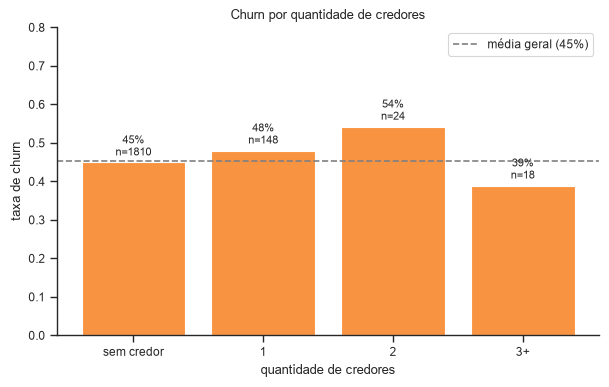

In [9]:
leads['grupo_credores'] = leads['qtd_credores'].clip(upper=3).map({0: 'sem credor', 1: '1', 2: '2', 3: '3+'})
fig, ax = plot.subplots(figsize=(7, 4))
barras_taxa(taxa(leads, 'grupo_credores', ['sem credor', '1', '2', '3+']), ax, 'Churn por quantidade de credores')
ax.set_xlabel('quantidade de credores')
seaborn.despine()
plot.show()

## Credor x negativações

Quem tem credor é quem tem negativação?

In [10]:
leads['tem_negativacao'] = leads['serasa_contagem_negativacoes'] > 0
print('% com negativação, entre quem tem e quem não tem credor:')
print((leads.groupby('tem_credor')['tem_negativacao'].mean() * 100).round(1).to_string())

rho, p = stats.spearmanr(leads['qtd_credores'], leads['serasa_contagem_negativacoes'])
print(f'Spearman (qtd de credores x qtd de negativações): {rho:+.2f}')

print('\nchurn entre os leads com negativação, com e sem credor:')
taxa(leads[leads['tem_negativacao']], 'tem_credor')

% com negativação, entre quem tem e quem não tem credor:
tem_credor
False      3.9
True     100.0
Spearman (qtd de credores x qtd de negativações): +0.84

churn entre os leads com negativação, com e sem credor:


,leads,taxa_churn
tem_credor,,
False,71,38.0
True,190,47.9


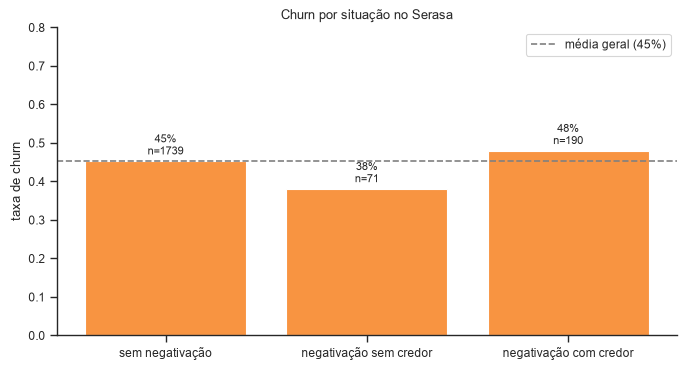

In [11]:
# como todo lead com credor tem negativação, os grupos possíveis são só 3
leads['situacao_serasa'] = np.select([leads['tem_credor'], leads['tem_negativacao']],
                                     ['negativação com credor', 'negativação sem credor'], 'sem negativação')
ordem_serasa = ['sem negativação', 'negativação sem credor', 'negativação com credor']

fig, ax = plot.subplots(figsize=(8, 4))
barras_taxa(taxa(leads, 'situacao_serasa', ordem_serasa), ax, 'Churn por situação no Serasa')
seaborn.despine()
plot.show()

## Credor x comportamento de compra e porte

O credor muda o churn **depois de descontar** outra variável? Uso o odds ratio de Mantel-Haenszel: efeito de ter credor dentro de cada grupo (OR ≈ 1 = nada; OR > 1 = ter credor aumenta a chance de churn).

,OR
odds ratio de ter credor,
bruto (sem descontar nada),1.13
descontando nº de pedidos,1.06
descontando recência (só quem tem pedido),1.16
descontando capital social,1.18
descontando idade do CNPJ,1.11


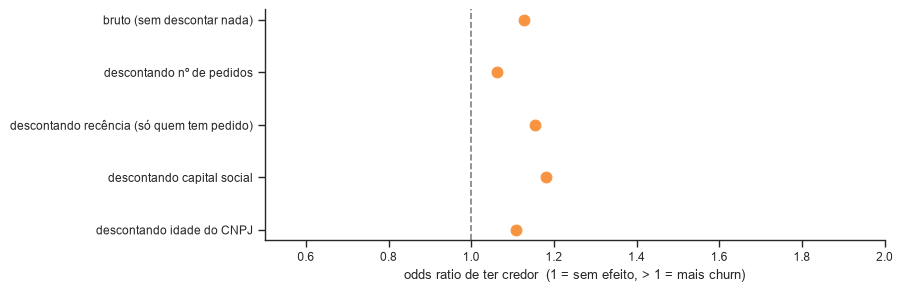

In [12]:
pedidos['data'] = pandas.to_datetime(pedidos['data_entrega'])
por_cliente = pedidos.groupby('id_cliente').agg(n_pedidos=('id_pedido', 'count'), ultima=('data', 'max'))
por_cliente['recencia_dias'] = (pedidos['data'].max() - por_cliente['ultima']).dt.days

base = leads.merge(por_cliente[['n_pedidos', 'recencia_dias']], left_on='id_cliente', right_index=True, how='left')
base['n_pedidos'] = base['n_pedidos'].fillna(0)
base['faixa_pedidos'] = pandas.cut(base['n_pedidos'], [-1, 0, 1, 4, np.inf], labels=['0', '1', '2-4', '5+'])
base['faixa_recencia'] = pandas.cut(base['recencia_dias'], [-1, 15, 30, np.inf], labels=['0-15d', '16-30d', '31d+'])

limite_inferior = lambda faixa: float(faixa.strip('()[]').split(',')[0])
base['grupo_capital'] = pandas.cut(base['capital_social'].map(limite_inferior), [-np.inf, 2000, 8000, 20000, np.inf],
                                   labels=['até 2 mil', '2-8 mil', '8-20 mil', '20 mil+'], right=False)
base['tempo_de_casa'] = pandas.cut(base['idade_cnpj'].map(limite_inferior), [-np.inf, 1600, np.inf],
                                   labels=['nova (< 4 anos)', 'antiga'], right=False)


def odds_ratio_mh(df, estrato):
    num = den = 0
    for _, d in df.groupby(estrato, observed=True):
        a, b = (d.tem_credor & (d.churned == 1)).sum(), (d.tem_credor & (d.churned == 0)).sum()
        c, e = (~d.tem_credor & (d.churned == 1)).sum(), (~d.tem_credor & (d.churned == 0)).sum()
        num += a * e / len(d)
        den += b * c / len(d)
    return num / den


com_ped = base[base['n_pedidos'] > 0]
ct = pandas.crosstab(base['tem_credor'], base['churned'])
linhas = [('bruto (sem descontar nada)', ct.loc[True, 1] * ct.loc[False, 0] / (ct.loc[True, 0] * ct.loc[False, 1]))]
for rotulo, df, estrato in [('descontando nº de pedidos', base, 'faixa_pedidos'),
                            ('descontando recência (só quem tem pedido)', com_ped, 'faixa_recencia'),
                            ('descontando capital social', base, 'grupo_capital'),
                            ('descontando idade do CNPJ', base, 'tempo_de_casa')]:
    linhas.append((rotulo, odds_ratio_mh(df, estrato)))
resultado_or = pandas.DataFrame(linhas, columns=['odds ratio de ter credor', 'OR']).set_index('odds ratio de ter credor')
display(resultado_or.round(2))

fig, ax = plot.subplots(figsize=(8, 3))
ax.scatter(resultado_or['OR'], range(len(resultado_or)), color=COR, s=60, zorder=3)
ax.axvline(1, color='gray', linestyle='--')
ax.set_yticks(range(len(resultado_or)), resultado_or.index)
ax.invert_yaxis()
ax.set_xlim(0.5, 2)
ax.set_xlabel('odds ratio de ter credor  (1 = sem efeito, > 1 = mais churn)')
seaborn.despine()
plot.show()

**Conclusão:**
- A quantidade de credores não tem relação com o churn (1 credor 48%, 2 = 54%, 3+ = 39%; Spearman ≈ 0). Ter ou não ter credor também muda pouco (48% x 45%)
- Todos os 190 leads com credor também têm negativação (contra ~4% de quem não tem credor), e a quantidade de credores acompanha a de negativações (Spearman ≈ 0,84). Ou seja, credor é quase um subconjunto de negativação
- Descontando pedidos, recência, capital social ou idade do CNPJ, o odds ratio fica entre 1,06 e 1,18 (bruto 1,13), ou seja, perto de 1: o credor não acrescenta quase nada ao que essas variáveis já explicam
- `tem_credor` e `qtd_credores` parecem dispensáveis no modelo (redundantes com negativações e cobrem só 9,5% dos leads)